# Classification PlantVillage Complet (38 classes — `mohitsingh1804/plantvillage`) —   Optimisé GPU T4

Ce notebook télécharge directement le dataset Kaggle complet **`mohitsingh1804/plantvillage`** (les **38 classes** originales de PlantVillage, ~54 300 images) dans Google Colab et entraîne un classifieur
### Améliorations intégrées :
1. **Détection récursive des dossiers d'images (`os.walk`)** : s'adapte automatiquement à l'arborescence de `mohitsingh1804/plantvillage` (sous-dossiers `train`/`val` ou autres).
2. **Déduplication par empreinte MD5** avant le split stratifié (70 % / 15 % / 15 %) pour éliminer tout doublon exact et éviter le *data leakage*.
3. **Suppression de la double pénalisation** (pas de `WeightedRandomSampler` cumulé à une perte pondérée) : remplacée par du **Label Smoothing (`0.1`)** et des poids lissés par racine carrée inverse.
4. **Augmentations spatiales  (train uniquement)** : `RandomResizedCrop`, `RandomRotation`, , retournements.
5. **Régularisation renforcée** : `Dropout(0.35)`, `weight_decay=1e-2` (AdamW), *gradient clipping*, et learning rate réduit lors du dégel du backbone (`3e-5`).
6. **Early Stopping sur `val_loss`** (patience = 4 époques) et sauvegarde de `best.pt` sur la meilleure perte de validation.
7. **Optimisé Colab T4 gratuit** : Mixed Precision (AMP FP16), reprise automatique via Google Drive (`latest.pt`), et export TorchScript + ONNX.


In [1]:
# 1. Installation des dépendances (ne pas réinstaller torch/torchvision pour garder CUDA Colab)
%pip install -q kagglehub scikit-learn matplotlib seaborn tqdm onnx


In [2]:
# 2. Montage de Google Drive et configuration
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, os, random, time, hashlib, zipfile, collections
import numpy as np
import torch

# Vérification du GPU T4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print(f'VRAM disponible: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} Go')

# --- Hyperparamètres adaptés au GPU T4 gratuit ---
DATASET_SLUG = 'mohitsingh1804/plantvillage'
BACKBONE = 'mobilenet_v3'       # 'mobilenet_v3' (rapide sur T4) ou 'resnet50'
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32 if BACKBONE == 'mobilenet_v3' else 16
NUM_WORKERS = 2

HEAD_EPOCHS = 3                 # Phase 1 : tête uniquement (backbone gelé)
MAX_EPOCHS = 20                 # Phase 2 : fine-tuning complet avec Early Stopping
EARLY_STOPPING_PATIENCE = 4     # Arrêt si val_loss ne s'améliore pas pendant 4 époques
LABEL_SMOOTHING = 0.1
DROPOUT_RATE = 0.35
WEIGHT_DECAY = 1e-2
USE_SMOOTHED_CLASS_WEIGHTS = True

MAX_MINUTES_PER_SESSION = 45    # Sécurité anti-déconnexion Colab

WORK_ROOT = Path('/content/drive/MyDrive/plant-disease/kaggle_plantvillage_38_classifier')
RUN_ROOT = WORK_ROOT / f'runs/{BACKBONE}'
RUN_ROOT.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print('Dossier de sauvegarde:', RUN_ROOT)


Mounted at /content/drive
Device: cuda
GPU: Tesla T4
VRAM disponible: 15.64 Go
Dossier de sauvegarde: /content/drive/MyDrive/plant-disease/kaggle_plantvillage_38_classifier/runs/mobilenet_v3


## 1. Téléchargement et scan récursif du dataset (`mohitsingh1804/plantvillage`)

`kagglehub` télécharge directement le dataset complet dans le stockage local rapide de Colab. Le scan récursif (`os.walk`) détecte automatiquement tous les dossiers contenant des images, quelle que soit la profondeur des sous-dossiers.


In [3]:
import kagglehub

dataset_path = Path(kagglehub.dataset_download(DATASET_SLUG))
print('Dataset téléchargé dans :', dataset_path)

VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Recherche récursive de tous les dossiers contenant directement des images
CLASS_TO_DIRS = collections.defaultdict(list)
for root, _, files in os.walk(dataset_path):
    img_files = [f for f in files if Path(f).suffix.lower() in VALID_EXTS]
    if img_files:
        folder = Path(root)
        CLASS_TO_DIRS[folder.name].append(folder)

if not CLASS_TO_DIRS:
    raise RuntimeError(f"Aucun dossier d'images trouvé dans {dataset_path}")

CLASS_NAMES = sorted(CLASS_TO_DIRS.keys())
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

print(f'{len(CLASS_NAMES)} classes détectées :')
for idx, name in enumerate(CLASS_NAMES):
    print(f'  {idx:2d}: {name} ({len(CLASS_TO_DIRS[name])} dossier(s))')


Using Colab cache for faster access to the 'plantvillage' dataset.
Dataset téléchargé dans : /kaggle/input/plantvillage
38 classes détectées :
   0: Apple___Apple_scab (2 dossier(s))
   1: Apple___Black_rot (2 dossier(s))
   2: Apple___Cedar_apple_rust (2 dossier(s))
   3: Apple___healthy (2 dossier(s))
   4: Blueberry___healthy (2 dossier(s))
   5: Cherry_(including_sour)___Powdery_mildew (2 dossier(s))
   6: Cherry_(including_sour)___healthy (2 dossier(s))
   7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot (2 dossier(s))
   8: Corn_(maize)___Common_rust_ (2 dossier(s))
   9: Corn_(maize)___Northern_Leaf_Blight (2 dossier(s))
  10: Corn_(maize)___healthy (2 dossier(s))
  11: Grape___Black_rot (2 dossier(s))
  12: Grape___Esca_(Black_Measles) (2 dossier(s))
  13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot) (2 dossier(s))
  14: Grape___healthy (2 dossier(s))
  15: Orange___Haunglongbing_(Citrus_greening) (2 dossier(s))
  16: Peach___Bacterial_spot (2 dossier(s))
  17: Peach___healt

## 2. Déduplication MD5 (Anti-Data Leakage) et Split Stratifié (70% / 15% / 15%)

On élimine d'abord les doublons exacts par hachage MD5 avant de séparer en `train`, `val` et `test` de manière stratifiée.


In [4]:
from sklearn.model_selection import train_test_split

def file_md5(path: Path) -> str:
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(65536), b''): #read per block de 64Ko (1024*64= 65536)
            h.update(chunk)
    return h.hexdigest()

seen_hashes = set()
samples = []
duplicates_removed = 0

for class_name in CLASS_NAMES:
    class_id = CLASS_TO_ID[class_name]
    for class_dir in CLASS_TO_DIRS[class_name]:
        for img_path in sorted(class_dir.iterdir()):
            if not img_path.is_file() or img_path.suffix.lower() not in VALID_EXTS:
                continue
            digest = file_md5(img_path)
            if digest in seen_hashes:
                duplicates_removed += 1
                continue
            seen_hashes.add(digest)
            samples.append((str(img_path), class_id))

print(f'Images uniques conservées : {len(samples)} (doublons exacts retirés : {duplicates_removed})')

labels_all = [cid for _, cid in samples]
train_samples, temp_samples, _, temp_labels = train_test_split(
    samples, labels_all, test_size=0.30, random_state=SEED, stratify=labels_all
)
val_samples, test_samples = train_test_split(
    temp_samples, test_size=0.50, random_state=SEED, stratify=temp_labels
)

splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}
for name, rows in splits.items():
    counts = collections.Counter(cid for _, cid in rows)
    print(f'{name:5s}: {len(rows):5d} images | min/max par classe: {min(counts.values())}/{max(counts.values())}')


Images uniques conservées : 54284 (doublons exacts retirés : 21)
train: 37998 images | min/max par classe: 106/3855
val  :  8143 images | min/max par classe: 23/826
test :  8143 images | min/max par classe: 23/826


## 3. Augmentations Anti-Overfitting et DataLoaders

- **Train** : `RandomResizedCrop`, rotations, retournements, variations de couleur et `RandomErasing` (Cutout).
- **Val / Test** : redimensionnement déterministe uniquement.
- **Pas de `WeightedRandomSampler`** : on évite la double pénalisation des classes rares.


In [5]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.65, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.00),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class LeafDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        path, label = self.rows[idx]
        with Image.open(path) as img:
            img = img.convert('RGB')
        return self.transform(img), torch.tensor(label, dtype=torch.long)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator().manual_seed(SEED)

loaders = {
    'train': DataLoader(
        LeafDataset(splits['train'], train_transform),
        batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker, generator=g, drop_last=True,
    ),
    'val': DataLoader(
        LeafDataset(splits['val'], eval_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    ),
    'test': DataLoader(
        LeafDataset(splits['test'], eval_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    ),
}

# Poids de classes doux (racine carrée inverse) pour équilibrer sans surapprentissage
train_counts = np.bincount([cid for _, cid in splits['train']], minlength=len(CLASS_NAMES)).astype(np.float64)
raw_weights = 1.0 / np.sqrt(np.maximum(train_counts, 1.0))
smoothed_weights = raw_weights / raw_weights.mean()
print('Poids de classes lissés (min/max):', round(smoothed_weights.min(), 3), '/', round(smoothed_weights.max(), 3))


Poids de classes lissés (min/max): 0.408 / 2.461


## 4. Modèle (avec Dropout), Perte (Label Smoothing) et Reprise sur Checkpoint


In [6]:
import torch.nn as nn
from torchvision.models import (
    mobilenet_v3_large, MobileNet_V3_Large_Weights,
    resnet50, ResNet50_Weights,
)

# ==============================================================================
# 1. MODEL CONSTRUCTION (Transfer Learning + Anti-Overfitting Dropout)
# ==============================================================================
def build_model(backbone: str, num_classes: int, dropout: float):
    if backbone == 'mobilenet_v3':
        # Load MobileNetV3-Large pretrained on ImageNet
        m = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
        # Get the number of input features going into the final classification layer
        in_features = m.classifier[-1].in_features
        # Replace the existing dropout layer with our custom dropout rate
        m.classifier[-2] = nn.Dropout(p=dropout, inplace=True)
        # Replace the final linear layer (1000 ImageNet classes -> our num_classes)
        m.classifier[-1] = nn.Linear(in_features, num_classes)
    elif backbone == 'resnet50':
        # Load ResNet-50 pretrained on ImageNet
        m = resnet50(weights=ResNet50_Weights.DEFAULT)
        # Get the number of input features going into the final fully connected (fc) layer
        in_features = m.fc.in_features
        # Replace the fc layer with Dropout + new Linear layer for our classes
        m.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_features, num_classes),
        )
    else:
        raise ValueError("BACKBONE doit être 'mobilenet_v3' ou 'resnet50'")
    return m

# Instantiate the model and move it to GPU (cuda) or CPU
model = build_model(BACKBONE, len(CLASS_NAMES), DROPOUT_RATE).to(device)

# ==============================================================================
# 2. LOSS FUNCTION (Smoothed Class Weights + Label Smoothing)
# ==============================================================================
# Convert smoothed class weights to a GPU tensor if enabled; otherwise None
loss_weight = torch.from_numpy(smoothed_weights).float().to(device) if USE_SMOOTHED_CLASS_WEIGHTS else None
# CrossEntropyLoss with optional class weights and label smoothing (prevents overconfidence/overfitting)
criterion = nn.CrossEntropyLoss(weight=loss_weight, label_smoothing=LABEL_SMOOTHING)

# ==============================================================================
# 3. FREEZING / UNFREEZING THE BACKBONE (Two-Stage Training)
# ==============================================================================
def set_backbone_trainable(m, trainable: bool):
    if BACKBONE == 'mobilenet_v3':
        # Freeze or unfreeze all feature-extraction layers (everything except the classifier head)
        for p in m.features.parameters():
            p.requires_grad = trainable
    else:
        # For ResNet-50, freeze or unfreeze every layer except the final 'fc' head
        for name, p in m.named_parameters():
            if not name.startswith('fc.'):
                p.requires_grad = trainable

# ==============================================================================
# 4. OPTIMIZER SETUP (Differential Learning Rates for Fine-Tuning)
# ==============================================================================
def build_optimizer(fine_tuning: bool):
    if fine_tuning:
        # Stage 2: Unfreeze the entire backbone so all weights can adapt to plant leaves
        set_backbone_trainable(model, True)
        if BACKBONE == 'mobilenet_v3':
            backbone_params = model.features.parameters()
            head_params = model.classifier.parameters()
        else:
            backbone_params = (p for n, p in model.named_parameters() if not n.startswith('fc.'))
            head_params = model.fc.parameters()
        # Use a very small LR (3e-5) for pretrained backbone to preserve ImageNet features,
        # and a 10x larger LR (3e-4) for the classification head
        return torch.optim.AdamW([
            {'params': backbone_params, 'lr': 3e-5},
            {'params': head_params, 'lr': 3e-4},
        ], weight_decay=WEIGHT_DECAY)
    else:
        # Stage 1: Freeze the backbone and train ONLY the newly initialized classifier head
        set_backbone_trainable(model, False)
        return torch.optim.AdamW(
            (p for p in model.parameters() if p.requires_grad),
            lr=1e-3,
            weight_decay=WEIGHT_DECAY,
        )

# Initialize Stage 1 optimizer, cosine LR scheduler, and AMP GradScaler (for FP16 speed on T4 GPU)
optimizer = build_optimizer(fine_tuning=False)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HEAD_EPOCHS)
scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')

# ==============================================================================
# 5. ATOMIC CHECKPOINT SAVING (Safe against Colab disconnects)
# ==============================================================================
def save_checkpoint(next_epoch, best_val_loss, best_val_acc, no_improve, history, name='latest.pt'):
    # Bundle everything needed to resume training seamlessly or run inference later
    payload = {
        'next_epoch': next_epoch,
        'best_val_loss': best_val_loss,
        'best_val_acc': best_val_acc,
        'no_improve': no_improve,
        'history': history,
        'backbone': BACKBONE,
        'class_names': CLASS_NAMES,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'scaler': scaler.state_dict(),
    }
    # Write to a temporary file first, then atomically rename it so a sudden disconnect
    # never leaves a half-written/corrupted checkpoint file
    tmp = RUN_ROOT / f'.{name}.tmp'
    torch.save(payload, tmp)
    tmp.replace(RUN_ROOT / name)

# ==============================================================================
# 6. AUTOMATIC RESUME FROM GOOGLE DRIVE CHECKPOINT
# ==============================================================================
# Reprise automatique si un checkpoint existe déjà dans Drive
history = []
best_val_loss = float('inf')  # Start at infinity so the first epoch's val_loss is always better
best_val_acc = 0.0
no_improve = 0                # Counter for Early Stopping patience
start_epoch = 0

latest_path = RUN_ROOT / 'latest.pt'
if latest_path.exists():
    # Load the saved checkpoint onto the current device (GPU/CPU)
    ckpt = torch.load(latest_path, map_location=device)
    # Verify the checkpoint matches the current backbone and class list before loading
    if ckpt.get('backbone') == BACKBONE and ckpt.get('class_names') == CLASS_NAMES:
        # Restore model weights and training progress trackers
        model.load_state_dict(ckpt['model'])
        history = ckpt.get('history', [])
        best_val_loss = ckpt.get('best_val_loss', float('inf'))
        best_val_acc = ckpt.get('best_val_acc', 0.0)
        no_improve = ckpt.get('no_improve', 0)
        start_epoch = ckpt.get('next_epoch', 0)

        # Rebuild optimizer & scheduler for the exact stage we left off in (Stage 1 vs Stage 2)
        fine_tuning = start_epoch >= HEAD_EPOCHS
        optimizer = build_optimizer(fine_tuning)
        t_max = max(MAX_EPOCHS - HEAD_EPOCHS, 1) if fine_tuning else HEAD_EPOCHS
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=t_max)

        # Restore optimizer momentum, LR scheduler step, and FP16 scaler state
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        scaler.load_state_dict(ckpt['scaler'])
        print(f"Reprise à l'époque {start_epoch + 1} | meilleur val_loss={best_val_loss:.4f} | val_acc={best_val_acc:.4f}")
    else:
        print("Checkpoint incompatible détecté, démarrage d'un nouvel entraînement.")
else:
    # No previous checkpoint found: print total number of parameters (in millions) and start fresh
    print(f'Nouvel entraînement {BACKBONE} ({sum(p.numel() for p in model.parameters())/1e6:.2f}M paramètres)')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 155MB/s]


Nouvel entraînement mobilenet_v3 (4.25M paramètres)


## 5. Boucle d'entraînement (AMP FP16 + Early Stopping sur `val_loss`)


In [7]:
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

session_deadline = time.time() + MAX_MINUTES_PER_SESSION * 60
stage2_started = start_epoch >= HEAD_EPOCHS

try:
    for epoch in range(start_epoch, MAX_EPOCHS):
        if epoch == HEAD_EPOCHS and not stage2_started:
            print(f"\n--- Dégel du backbone à l'époque {epoch + 1} (LR backbone=3e-5, head=3e-4) ---")
            optimizer = build_optimizer(fine_tuning=True)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=max(MAX_EPOCHS - HEAD_EPOCHS, 1)
            )
            stage2_started = True

        # --- TRAIN ---
        model.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0
        pbar = tqdm(loaders['train'], desc=f'Epoch {epoch+1:02d}/{MAX_EPOCHS} [Train]')
        for images, labels in pbar:
            if time.time() >= session_deadline:
                save_checkpoint(epoch, best_val_loss, best_val_acc, no_improve, history)
                print('Limite de session atteinte. Relancez simplement pour reprendre.')
                raise TimeoutError

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (logits.argmax(1) == labels).sum().item()
            train_total += labels.size(0)
            pbar.set_postfix(loss=f'{loss.item():.4f}')

        train_loss = train_loss_sum / max(train_total, 1)
        train_acc = train_correct / max(train_total, 1)

        # --- VALIDATION ---
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for images, labels in loaders['val']:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                    logits = model(images)
                    loss = criterion(logits, labels)
                val_loss_sum += loss.item() * labels.size(0)
                preds = logits.argmax(1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                val_preds.append(preds.cpu().numpy())
                val_targets.append(labels.cpu().numpy())

        val_loss = val_loss_sum / max(val_total, 1)
        val_acc = val_correct / max(val_total, 1)
        val_macro_f1 = f1_score(np.concatenate(val_targets), np.concatenate(val_preds), average='macro')

        scheduler.step()

        row = {
            'epoch': epoch + 1,
            'train_loss': round(train_loss, 4),
            'val_loss': round(val_loss, 4),
            'train_acc': round(train_acc, 4),
            'val_acc': round(val_acc, 4),
            'val_macro_f1': round(float(val_macro_f1), 4),
        }
        history.append(row)
        print(row)

        # Sauvegarde du meilleur modèle sur val_loss (plus fiable contre l'overfitting)
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_val_acc = val_acc
            no_improve = 0
            save_checkpoint(epoch + 1, best_val_loss, best_val_acc, no_improve, history, 'best.pt')
        else:
            no_improve += 1

        save_checkpoint(epoch + 1, best_val_loss, best_val_acc, no_improve, history, 'latest.pt')

        if epoch >= HEAD_EPOCHS and no_improve >= EARLY_STOPPING_PATIENCE:
            print(f"Early Stopping déclenché à l'époque {epoch + 1} (val_loss stable depuis {EARLY_STOPPING_PATIENCE} époques).")
            break

except TimeoutError:
    pass


Epoch 01/20 [Train]:   0%|          | 0/1187 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.4235, 'val_loss': 1.1752, 'train_acc': 0.8653, 'val_acc': 0.9379, 'val_macro_f1': 0.919}


Epoch 02/20 [Train]:   0%|          | 0/1187 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.2057, 'val_loss': 1.1194, 'train_acc': 0.9293, 'val_acc': 0.9524, 'val_macro_f1': 0.9396}


Epoch 03/20 [Train]:   0%|          | 0/1187 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.1293, 'val_loss': 1.0684, 'train_acc': 0.9513, 'val_acc': 0.9665, 'val_macro_f1': 0.959}

--- Dégel du backbone à l'époque 4 (LR backbone=3e-5, head=3e-4) ---


... (12 outputs left out)

Epoch 10/20 [Train]:   0%|          | 0/1187 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.9032, 'val_loss': 0.8894, 'train_acc': 0.9976, 'val_acc': 0.9975, 'val_macro_f1': 0.9961}


Epoch 11/20 [Train]:   0%|          | 0/1187 [00:00<?, ?it/s]

Limite de session atteinte. Relancez simplement pour reprendre.


## 6. Courbes d'apprentissage (Vérification visuelle de l'overfitting)


,epoch,train_loss,val_loss,train_acc,val_acc,val_macro_f1
0,1,1.4235,1.1752,0.8653,0.9379,0.9190
1,2,1.2057,1.1194,0.9293,0.9524,0.9396
2,3,1.1293,1.0684,0.9513,0.9665,0.9590
3,4,1.0518,0.9770,0.9725,0.9854,0.9802
4,5,0.9824,0.9498,0.9876,0.9899,0.9874
5,6,0.9522,0.9191,0.9923,0.9952,0.9932
6,7,0.9327,0.9152,0.9948,0.9941,0.9902
7,8,0.9200,0.9019,0.9960,0.9968,0.9950
8,9,0.9108,0.8931,0.9968,0.9973,0.9964
9,10,0.9032,0.8894,0.9976,0.9975,0.9961


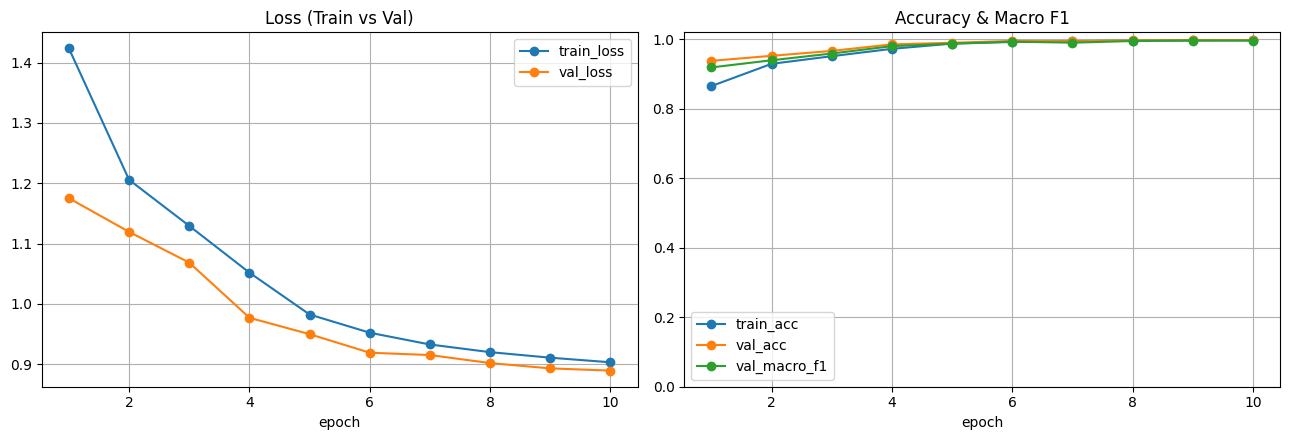

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv(RUN_ROOT / 'history.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
history_df.plot(x='epoch', y=['train_loss', 'val_loss'], marker='o', ax=axes[0], title='Loss (Train vs Val)')
axes[0].grid(True)

history_df.plot(x='epoch', y=['train_acc', 'val_acc', 'val_macro_f1'], marker='o', ax=axes[1], title='Accuracy & Macro F1', ylim=(0, 1.02))
axes[1].grid(True)

plt.tight_layout()
plt.savefig(RUN_ROOT / 'learning_curves.png', dpi=150)
plt.show()


## 7. Évaluation finale sur le jeu de test & Export (TorchScript / ONNX)


Test:   0%|          | 0/255 [00:00<?, ?it/s]

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    1.0000    1.0000        94
                                 Apple___Black_rot     1.0000    1.0000    1.0000        93
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        41
                                   Apple___healthy     1.0000    1.0000    1.0000       245
                               Blueberry___healthy     1.0000    1.0000    1.0000       226
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000       158
                 Cherry_(including_sour)___healthy     1.0000    1.0000    1.0000       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9722    0.9091    0.9396        77
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       179
               Corn_(maize)___Northern_Leaf_Blight     0.9536    0.9796    0.96

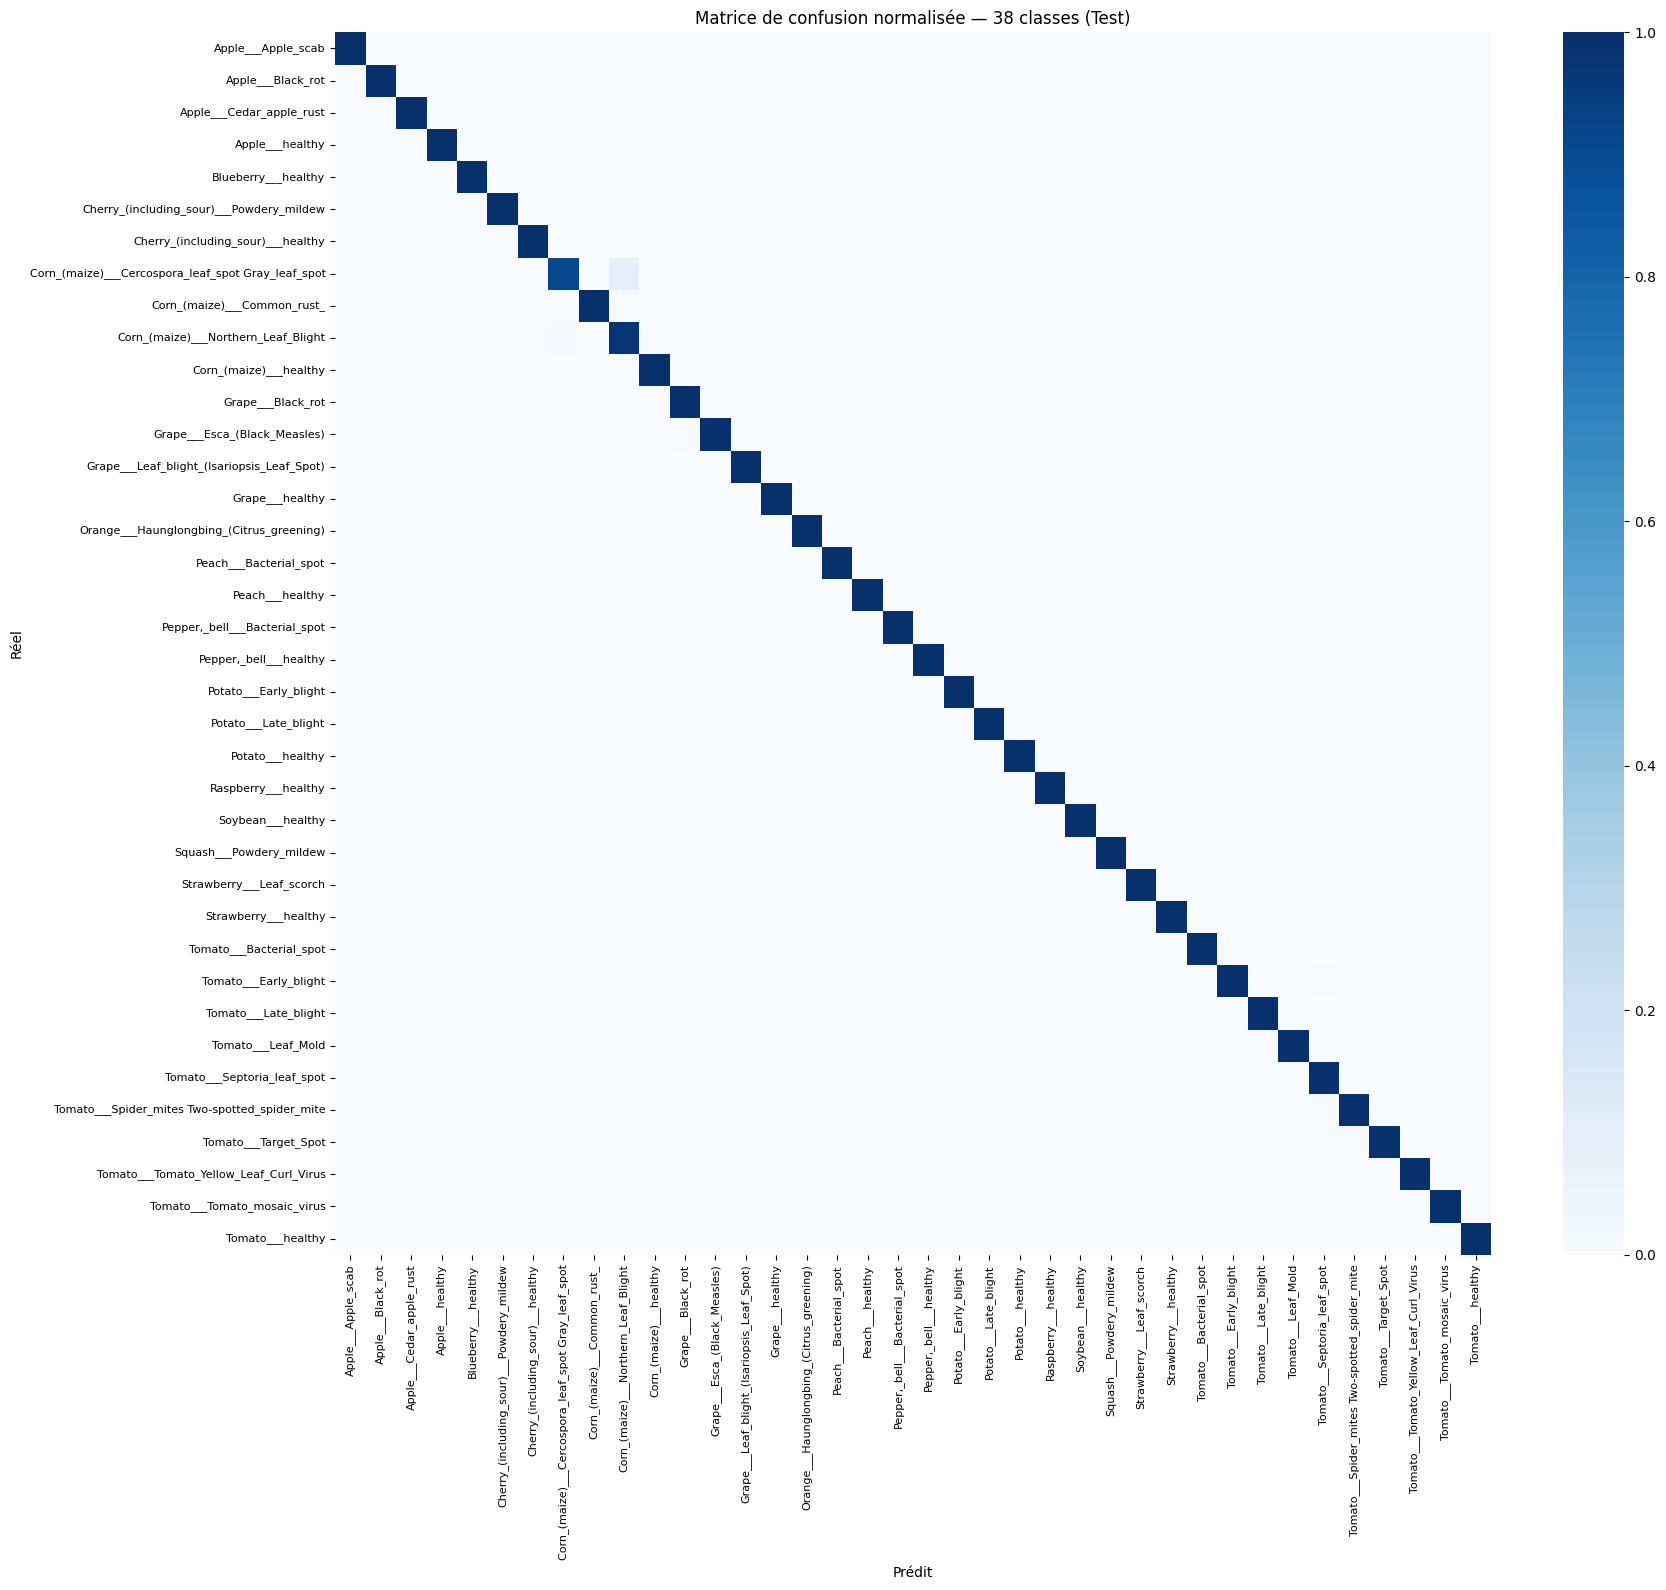

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Export ONNX ignoré : No module named 'onnxscript'
Export terminé : /content/drive/MyDrive/plant-disease/kaggle_plantvillage_38_classifier/plantvillage_38_mobilenet_v3_export.zip


In [9]:
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score, f1_score
import seaborn as sns

best_ckpt = torch.load(RUN_ROOT / 'best.pt', map_location=device)
model.load_state_dict(best_ckpt['model'])
model.eval()

y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for images, labels in tqdm(loaders['test'], desc='Test'):
        images = images.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(images)
        probs = logits.float().softmax(dim=1).cpu().numpy()
        y_prob.append(probs)
        y_pred.append(probs.argmax(axis=1))
        y_true.append(labels.numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
y_prob = np.concatenate(y_prob)

top1 = float((y_true == y_pred).mean())
top3 = float(top_k_accuracy_score(y_true, y_prob, k=3, labels=np.arange(len(CLASS_NAMES))))
macro_f1 = float(f1_score(y_true, y_pred, average='macro'))
weighted_f1 = float(f1_score(y_true, y_pred, average='weighted'))

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f'Top-1 Accuracy : {top1:.4f}')
print(f'Top-3 Accuracy : {top3:.4f}')
print(f'Macro F1       : {macro_f1:.4f}')
print(f'Weighted F1    : {weighted_f1:.4f}')

# Matrice de confusion normalisée par ligne (adaptée pour 38 classes)
cm = confusion_matrix(y_true, y_pred, normalize='true')
plt.figure(figsize=(18, 16))
sns.heatmap(cm, cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.title('Matrice de confusion normalisée — 38 classes (Test)')
plt.tight_layout()
plt.savefig(RUN_ROOT / 'confusion_matrix_normalized.png', dpi=150)
plt.show()

metrics = {
    'dataset': DATASET_SLUG,
    'backbone': BACKBONE,
    'num_classes': len(CLASS_NAMES),
    'top1_accuracy': top1,
    'top3_accuracy': top3,
    'macro_f1': macro_f1,
    'weighted_f1': weighted_f1,
    'class_names': CLASS_NAMES,
}
(RUN_ROOT / 'test_metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')

# Export des modèles
model_cpu = model.eval().cpu()
dummy = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.jit.trace(model_cpu, dummy).save(str(RUN_ROOT / 'plantvillage_38_classifier.ts'))
torch.save(model_cpu.state_dict(), RUN_ROOT / 'plantvillage_38_state_dict.pt')

try:
    torch.onnx.export(
        model_cpu, dummy, str(RUN_ROOT / 'plantvillage_38_classifier.onnx'),
        input_names=['image'], output_names=['logits'],
        dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}},
        opset_version=17, do_constant_folding=True,
    )
except Exception as e:
    print('Export ONNX ignoré :', e)

(RUN_ROOT / 'model_config.json').write_text(json.dumps({
    'backbone': BACKBONE,
    'input_size': [IMAGE_SIZE, IMAGE_SIZE],
    'normalization_mean': IMAGENET_MEAN,
    'normalization_std': IMAGENET_STD,
    'class_names': CLASS_NAMES,
    'dataset': DATASET_SLUG,
}, indent=2) + '\n')

zip_path = WORK_ROOT / f'plantvillage_38_{BACKBONE}_export.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in [
        'plantvillage_38_classifier.ts', 'plantvillage_38_state_dict.pt',
        'plantvillage_38_classifier.onnx', 'model_config.json',
        'test_metrics.json', 'history.csv', 'learning_curves.png',
        'confusion_matrix_normalized.png', 'best.pt',
    ]:
        fpath = RUN_ROOT / fname
        if fpath.exists():
            zf.write(fpath, fname)

print('Export terminé :', zip_path)


In [10]:
%pip install -q onnxscript

torch.onnx.export(
    model_cpu, dummy, str(RUN_ROOT / 'plantvillage_38_classifier.onnx'),
    input_names=['image'], output_names=['logits'],
    dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
)
print('Export ONNX réussi :', RUN_ROOT / 'plantvillage_38_classifier.onnx')

/tmp/ipykernel_659/2753554346.py:3: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1121 14:24:30.276000 659 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Export ONNX réussi : /content/drive/MyDrive/plant-disease/kaggle_plantvillage_38_classifier/runs/mobilenet_v3/plantvillage_38_classifier.onnx
